# CreditRisk+ y el ajuste por granularidad

**Pregunta:** ¿Cuánto puede perder la cartera de 1.120 nombres según CreditRisk+, que no necesita simulación, y cuánto capital omite la fórmula de la cartera grande porque la cartera está concentrada?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 03 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook puedes:

- describir el modelo CreditRisk+, en que los incumplimientos son conteos de Poisson gobernados por un factor sectorial Gamma, y decir cómo se calcula su distribución de pérdidas sin simulación;
- correr la recursión estable en la cartera ilustrativa, comprobar su primera probabilidad contra una forma cerrada, y leer VaR y déficit esperado de la distribución exacta;
- mostrar en una cartera de estrés construida por qué la recursión original de tipo Panjer se conserva solo como comparación;
- enunciar el ajuste por granularidad de Gordy y Lutkebohmert, reproducir su vector de prueba, y calcularlo para la cartera a partir del capital IRB de cada grupo;
- leer la brecha entre la fórmula infinitamente granular y una cartera finita y concentrada, y decir dónde el ajuste la sobrestima;
- probar la recursión contra una muestra de Monte Carlo del mismo modelo.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import integrate, stats

# El cuaderno está tres carpetas por debajo de la raíz del repositorio
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

# Nombres de las luces de validación
LIGHTS = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Dos de los cinco archivos por tipo de préstamo del caso C10 (propietario: este repositorio; las tasas de pérdida detrás de los ajustes vienen de la tabla `chgallsa` de la Reserva Federal, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, dominio público, clase de licencia `mirror-allowed`):

- `data/derived/C10/commercial-industrial.json`: la cartera ilustrativa de 1.120 nombres (`outputs.portfolio`), el peldaño CreditRisk+ versionado (`outputs.rungs`, con sus parámetros y diagnósticos), el bloque de granularidad (`outputs.granularity`) y la fila de prueba de la recursión contra Monte Carlo (`tests`);
- `data/derived/C10/credit-cards.json`: los mismos bloques para la cartera de tarjetas de crédito, usado en el Paso 5 porque su tabla de granularidad trae la respuesta exacta de CreditRisk+ que le falta al archivo comercial.

La cartera es construida y está etiquetada `illustrative`, nunca la de un banco. La celda siguiente carga ambos archivos e imprime la cartera y los parámetros de CreditRisk+ del caso.

In [2]:
# Cargar los dos artefactos e imprimir la cartera y los parámetros de CreditRisk+ del caso
doc = json.loads((ROOT / "data" / "derived" / "C10" / "commercial-industrial.json").read_text(encoding="utf-8"))
cards = json.loads((ROOT / "data" / "derived" / "C10" / "credit-cards.json").read_text(encoding="utf-8"))
out = doc["outputs"]
book = out["portfolio"]
groups = book["groups"]
pd_hat = out["fit"]["maximum_likelihood"]["pd"]["estimate"]
rho_hat = out["fit"]["maximum_likelihood"]["rho"]["estimate"]
rungs = {r["id"]: r for r in out["rungs"]}
parameters = {p["name"]: p["value"] for p in rungs["c4-creditrisk-plus"]["parameters"]}
diagnostics = {d["name"]: d["value"] for d in rungs["c4-creditrisk-plus"]["diagnostics"]}

print("cartera:", book["n_names"], "nombres,", f"{book['total_ead']:,.0f}", book["currency"])
print("unidad de pérdida:", parameters["loss_unit"], "| largo de grilla:", int(diagnostics["n_max"]))

cartera: 1120 nombres, 100,000,000 USD
unidad de pérdida: 1000.0 | largo de grilla: 12728


## Método

### Paso 1: el modelo CreditRisk+

CreditRisk+ es la contraparte actuarial de los modelos de cópula. Las exposiciones son múltiplos enteros $\nu_i$ de una **unidad de pérdida** (aquí 1.000 USD de pérdida, es decir, exposición por LGD). El número de incumplimientos del nombre $i$ es Poisson con una intensidad que depende de un **factor sectorial** $S$ con distribución Gamma de media 1 y varianza $\sigma^2$, y la pérdida de la cartera en unidades es $X=\sum_i \nu_i Y_i$. Con un sector y sin peso idiosincrático, la intensidad del nombre $i$ es $p_i S$. La función generadora de probabilidad de la pérdida, el objeto desde el cual se calcula la distribución, es (Haaf, Reiss y Schoenmakers, 2004, https://doi.org/10.21314/jor.2004.097):

$$G(z) = \exp\!\left(-\frac{1}{\sigma^2}\ln\!\left[1-\sigma^2\sum_i p_i\,(z^{\nu_i}-1)\right]\right)$$

El modelo tiene límites que recordar: solo modo de incumplimiento, recuperaciones determinísticas en el modelo básico, y una aproximación de Poisson que puede dar varios incumplimientos de un mismo deudor cuando una PD es grande. La varianza Gamma es un parámetro que el caso fija por igualación de momentos: $\sigma^2$ es la varianza de la tasa de incumplimiento de Vasicek del notebook 01 sobre la PD al cuadrado, $\sigma^2=(E[p(Z)^2]-\mathrm{PD}^2)/\mathrm{PD}^2$. Es una elección de calibración, no una medida de riesgo. La celda siguiente construye el insumo del motor a partir de los grupos, calcula $\sigma^2$ por integración numérica de la PD condicional del notebook 01 e imprime las bandas de exposición.

In [3]:
# Construir el insumo de CreditRisk+ a partir de los grupos y calibrar sigma al cuadrado por integración numérica
from riskvalidation.engines.vasicek import conditional_pd
from riskvalidation.portfolio import creditrisk_plus as cr

loss_unit, lgd = parameters["loss_unit"], book["lgd_mean"]
ead = np.concatenate([np.full(g["n_names"], g["ead_each"]) for g in groups])
pd_names = np.concatenate([np.full(g["n_names"], g["pd"]) for g in groups])
units = np.rint(ead * lgd / loss_unit).astype(int)

density = lambda z: float(conditional_pd(pd_hat, rho_hat, z)) ** 2 * stats.norm.pdf(z)
second_moment, _ = integrate.quad(density, -12, 12, epsabs=1e-16, epsrel=1e-12, limit=200)
sigma2 = (second_moment - pd_hat ** 2) / pd_hat ** 2
inp = cr.CreditRiskPlusInput(
    nu=units, pd=pd_names, w0=np.zeros(ead.size), weights=np.ones((ead.size, 1)),
    sigma2=np.array([sigma2]), loss_unit=loss_unit, currency=book["currency"])

print("nombres:", ead.size, "| bandas de exposición (unidades de pérdida):", sorted(set(units.tolist())))
print("unidades totales:", int(units.sum()), "| número esperado de incumplimientos:", round(float(pd_names.sum()), 4))
print("sigma^2 =", round(sigma2, 9))

nombres: 1120 | bandas de exposición (unidades de pérdida): [9, 180, 900]
unidades totales: 45000 | número esperado de incumplimientos: 16.2877
sigma^2 = 0.552065603


### Paso 2: la recursión estable y su distribución exacta

Tomando logaritmos de la función generadora y expandiendo en potencias de $z$ se obtiene una recursión para las probabilidades $p_n=P(X=n)$. Si $\ln G(z)=\sum_{j\ge 0} a_j z^j$, entonces $p_0=e^{a_0}$ y $n\,p_n=\sum_{j=1}^{n} j\,a_j\,p_{n-j}$. En la forma estable de Haaf, Reiss y Schoenmakers (2004) todo coeficiente $a_j$ con $j\ge1$ es no negativo, así que no hay restas de términos de signo opuesto y ninguna probabilidad puede salir negativa. `pmf_stable` del motor calcula $p_0,\dots,p_{n_{\max}}$ y deja fuera la masa de la cola. Una forma cerrada la comprueba: con un sector, $P(X=0)=G(0)=(1+\sigma^2\mu)^{-1/\sigma^2}$ donde $\mu=\sum_i p_i$ es el número esperado de incumplimientos. `measures_from_pmf` lee entonces VaR y déficit esperado en la grilla de unidades con el estimador discreto de Acerbi y Tasche. La celda siguiente corre la recursión en la grilla del caso, comprueba $p_0$ y la masa faltante, y lee el VaR y el déficit esperado al 99% y al 99,9%.

In [4]:
# Correr la recursión estable, comprobar P(X = 0) con su forma cerrada y leer VaR y ES
n_max = int(diagnostics["n_max"])
pmf = cr.pmf_stable(inp, n_max)
mu = float(pd_names.sum())
print("n_max:", n_max, "| masa en la grilla:", round(float(pmf.sum()), 12))
print("entradas negativas:", int((pmf < 0).sum()))
print("P(X = 0) recursión:", f"{pmf[0]:.12e}", "| forma cerrada:", f"{(1 + sigma2 * mu) ** (-1 / sigma2):.12e}")

measures = cr.measures_from_pmf(pmf, loss_unit, (0.99, 0.999))
for m in measures:
    print(f"q = {m.level}: EL {m.el:,.0f} | VaR {m.var:,.0f} | ES {m.es:,.0f} | capital {m.ec:,.0f}")

n_max: 12728 | masa en la grilla: 1.0
entradas negativas: 0
P(X = 0) recursión: 1.546187529037e-02 | forma cerrada: 1.546187529037e-02
q = 0.99: EL 409,721 | VaR 2,079,000 | ES 2,514,778 | capital 1,669,279
q = 0.999: EL 409,721 | VaR 3,078,000 | ES 3,506,025 | capital 2,668,279


La recursión da toda la distribución de una vez. La celda siguiente dibuja su probabilidad de excedencia, la probabilidad de una pérdida sobre cada nivel, junto a dos referencias calculadas aquí: la cópula gaussiana de un factor (un Monte Carlo de 200.000 escenarios) y el límite de la cartera grande. CreditRisk+ con el $\sigma^2$ igualado por momentos y la cópula gaussiana describen la misma cartera con supuestos distintos, y las dos curvas son cercanas en el cuerpo y se separan en la cola lejana.

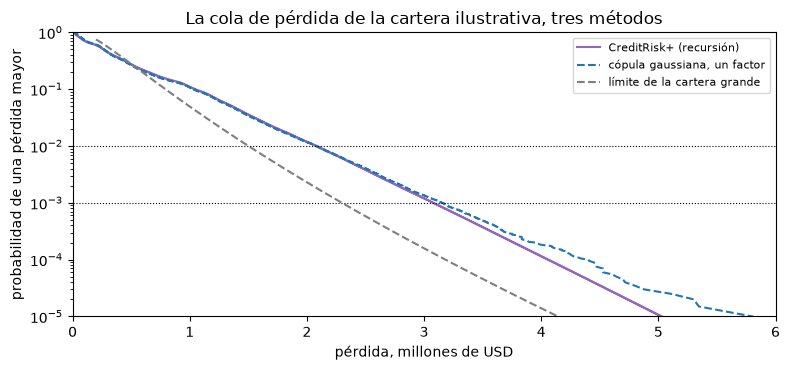

In [5]:
# Simular la cópula gaussiana de un factor y dibujar la cola de pérdida de tres métodos
from riskvalidation.engines.vasicek import lhp_cdf
from riskvalidation.portfolio import copula
from riskvalidation.portfolio import portfolio as pf

one = pf.portfolio_from_groups(groups, book["currency"], book["lgd_gamma"], one_factor=True)
sim = rungs["c2-gaussian-1f"]["simulation"]
sample = copula.simulate_gaussian(one, 200_000, sim["seed"], sim["chunk_size"])
ordered = np.sort(sample.losses)
exceed_mc = 1.0 - np.arange(1, ordered.size + 1) / ordered.size
limit_loss = np.linspace(0.2, 6.0, 300) * 1e6
exceed_lhp = 1 - lhp_cdf(limit_loss / (book["total_ead"] * lgd), pd_hat, rho_hat)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(np.arange(pmf.size) * loss_unit / 1e6, 1 - np.cumsum(pmf), color="tab:purple", label="CreditRisk+ (recursión)")
ax.plot(ordered[:-1] / 1e6, exceed_mc[:-1], color="tab:blue", linestyle="--", label="cópula gaussiana, un factor")
ax.plot(limit_loss / 1e6, exceed_lhp, color="tab:gray", linestyle="--", label="límite de la cartera grande")
for q in (0.99, 0.999):
    ax.axhline(1 - q, color="black", linestyle=":", linewidth=0.8)
ax.set_yscale("log")
ax.set_ylim(1e-5, 1)
ax.set_xlim(0, 6)
ax.set_xlabel("pérdida, millones de USD")
ax.set_ylabel("probabilidad de una pérdida mayor")
ax.set_title("La cola de pérdida de la cartera ilustrativa, tres métodos")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La curva morada es exacta, sin ruido de muestreo, y es suave hasta la línea del 0,1%, donde la curva simulada ya se vuelve irregular. CreditRisk+ y la cópula gaussiana simulada corren juntas, la primera algo bajo la segunda en la cola lejana, mientras ambas quedan muy a la derecha del límite gris de la cartera grande: la distancia entre la curva gris y las otras dos es la concentración de una cartera con cerca de 104 nombres efectivos. El acuerdo no valida a ninguna de las dos, pues los modelos comparten la PD y la correlación del ajuste y difieren en cómo generan los incumplimientos. La figura no dice qué cola tendría una cartera real.

### Paso 3: por qué la recursión original se conserva solo como comparación

La recursión del documento original de CreditRisk+ despeja los denominadores de la función generadora multiplicándolos. Eso resta términos de signo opuesto, y el error de redondeo puede dar entonces probabilidades negativas (la inestabilidad señalada por Haaf, Reiss y Schoenmakers, 2004). `pmf_panjer` del motor tiene la misma firma que `pmf_stable` y se conserva solo para mostrar esto; no recorta nada. En la cartera de este caso, con un sector, las dos coinciden hasta el redondeo. La celda siguiente las compara ahí y luego en una **cartera de estrés construida**: 30.000 nombres en 5 bandas de exposición, 8 sectores con varianzas Gamma de 0,02 a 12, y unos 1.800 incumplimientos esperados, sorteada con un generador con semilla. La cartera de estrés es sintética, construida aquí para mostrar la falla, y no es un caso del producto.

In [6]:
# Comparar las recursiones estable y de Panjer en la cartera del caso y en una cartera de estrés construida
panjer = cr.pmf_panjer(inp, n_max)
gap = np.abs(panjer - pmf).max()
print("cartera del caso: mayor diferencia", f"{gap:.1e}", "| entradas negativas de Panjer:", int((panjer < 0).sum()))

rng = np.random.default_rng(3)
n_stress, n_sectors = 30_000, 8
stress_units = rng.integers(1, 6, size=n_stress)
stress_pd = rng.uniform(0.03, 0.09, size=n_stress)
stress_w = rng.dirichlet(np.ones(n_sectors + 1), size=n_stress)
stress = cr.CreditRiskPlusInput(
    nu=stress_units, pd=stress_pd, w0=stress_w[:, 0], weights=stress_w[:, 1:],
    sigma2=np.array([0.02, 0.2, 0.8, 1.5, 3.0, 6.0, 9.0, 12.0]), loss_unit=1.0, currency="USD")
stable_s = cr.pmf_stable(stress, 6000)
panjer_s = cr.pmf_panjer(stress, 6000)

print("cartera de estrés:", n_stress, "nombres,", n_sectors, "sectores")
print("incumplimientos esperados:", round(float(stress.pd.sum())))
for label, p in (("stable", stable_s), ("Panjer", panjer_s)):
    outside = int(((p < 0) | (p > 1)).sum())
    print(f"{label:7s} entradas fuera de [0, 1]: {outside} | negativas: {int((p < 0).sum())} | suma: {p.sum():.3g}")

cartera del caso: mayor diferencia 2.1e-17 | entradas negativas de Panjer: 0
cartera de estrés: 30000 nombres, 8 sectores
incumplimientos esperados: 1802
stable  entradas fuera de [0, 1]: 0 | negativas: 0 | suma: 0.721
Panjer  entradas fuera de [0, 1]: 2406 | negativas: 2406 | suma: -7.01


### Paso 4: el ajuste por granularidad

La fórmula de la cartera grande supone nombres tan pequeños que el riesgo idiosincrático desaparece. Una cartera concentrada conserva algo de él, y el capital debe ser mayor. Gordy y Lutkebohmert (2013, https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf) dan un ajuste simplificado, una parte de la exposición, construido sobre el modelo CreditRisk+ de un factor con un factor Gamma de media 1 y varianza $1/\xi$:

$$\mathrm{GA}=\frac{1}{2K^*}\sum_i s_i^2\,C_i\,\big(\delta\,(K_i+R_i)-K_i\big),\qquad \delta=(\alpha_q-1)\left(\xi+\frac{1-\xi}{\alpha_q}\right)$$

donde $s_i$ es la participación de la exposición, $K_i$ el capital del nombre $i$ por unidad de exposición, $K^*=\sum_i s_iK_i$, $R_i=E[\mathrm{LGD}_i]\,\mathrm{PD}_i$ la reserva, $C_i=(V[\mathrm{LGD}_i]+E[\mathrm{LGD}_i]^2)/E[\mathrm{LGD}_i]$, $V[\mathrm{LGD}_i]=\gamma\,E[\mathrm{LGD}_i](1-E[\mathrm{LGD}_i])$ y $\alpha_q$ el cuantil $q$ del factor Gamma (ecuaciones 11, 15, 16 y 17 del artículo). El artículo da un vector de prueba: $\xi=0{,}25$ y $q=0{,}999$ dan $\delta=4{,}83$. `delta` y `gamma_quantile` del motor lo calculan; la celda siguiente reproduce el vector y muestra cómo se mueve $\delta$ con $\xi$ y $q$.

In [7]:
# Calcular la constante de granularidad delta para el vector de prueba del artículo y para otras precisiones y niveles
from riskvalidation.portfolio import granularity as gr

gran = out["granularity"]
xi_ref = gran["xi"]
alpha_ref = gr.gamma_quantile(xi_ref, 0.999)
print("xi =", xi_ref, "| q = 0.999 | alpha_q =", round(alpha_ref, 4), "| delta =", round(gr.delta(xi_ref, 0.999), 4))
print(f"{'xi':>6s} {'q = 0.99':>10s} {'q = 0.999':>10s} {'q = 0.9995':>11s}")
for xi in (0.25, 0.5, 1.0, 2.0):
    print(f"{xi:6.2f} {gr.delta(xi, 0.99):10.4f} {gr.delta(xi, 0.999):10.4f} {gr.delta(xi, 0.9995):11.4f}")

xi = 0.25 | q = 0.999 | alpha_q = 17.5058 | delta = 4.8336
    xi   q = 0.99  q = 0.999  q = 0.9995
  0.25     2.8568     4.8336      5.4482
  0.50     3.2421     5.3676      6.0166
  1.00     3.6052     5.9078      6.6009
  2.00     3.9396     6.4500      7.1987


La celda siguiente dibuja delta como función de la precisión del factor Gamma para tres niveles de confianza.

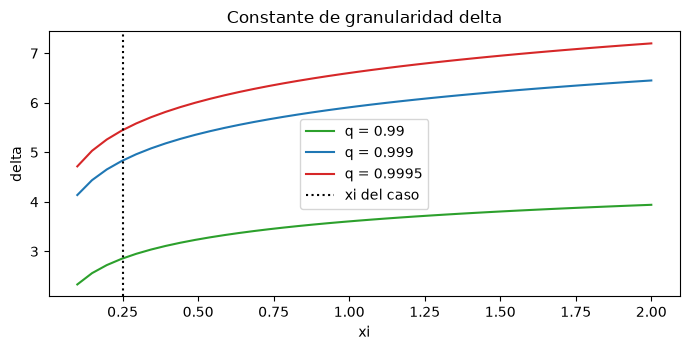

In [8]:
# Dibujar delta contra xi para tres niveles de confianza
xi_grid = np.linspace(0.1, 2.0, 40)
fig, ax = plt.subplots(figsize=(7, 3.6))
for level, color in ((0.99, "tab:green"), (0.999, "tab:blue"), (0.9995, "tab:red")):
    ax.plot(xi_grid, [gr.delta(x, level) for x in xi_grid], color=color, label=f"q = {level}")
ax.axvline(xi_ref, color="black", linestyle=":", label="xi del caso")
ax.set_xlabel("xi")
ax.set_ylabel("delta")
ax.set_title("Constante de granularidad delta")
ax.legend()
fig.tight_layout()
plt.show()

Delta crece con ambos argumentos: un nivel de confianza mayor empuja hacia afuera el cuantil Gamma y un xi mayor, que significa un factor menos volátil, hace pesar más la parte idiosincrática. Con el xi del caso, 0,25, la curva del 99,9% pasa por 4,83, el número que el artículo imprime como su vector de prueba, y el motor lo reproduce hasta los dígitos impresos. La figura solo muestra la constante; el tamaño del ajuste de una cartera concreta depende además de sus participaciones de exposición, PD y LGD, que introduce la celda siguiente. El modelo Gamma del ajuste es una aproximación del factor de Vasicek, así que la constante es una elección regulatoria y no una estimación.

Ahora el ajuste para la cartera. El capital $K_i$ de cada nombre es el capital IRB del grupo del nombre con su propia PD, una LGD de 45% y un vencimiento de 2,5 años (Basel Framework CRE31, https://www.bis.org/basel_framework/chapter/CRE/31.htm), como prescribe el algoritmo regulatorio del artículo. `capital_requirement` del motor lo devuelve y `granularity_adjustment` aplica la fórmula, con $\xi=0{,}25$ y $\gamma=0{,}25$ del artículo leídos del artefacto. El ajuste es una parte de la exposición; sumarlo al VaR de la cartera grande da el capital de la cartera con su concentración.

In [9]:
# Calcular el ajuste por granularidad de la cartera desde el capital IRB de cada grupo
from riskvalidation.portfolio.portfolio import lhp_measures
from riskvalidation.regulatory.irb import capital_requirement

k_group = {}
for g in groups:
    k_group[g["id"]] = float(capital_requirement("corporate", g["pd"], lgd, regime="basel3", maturity=2.5).k)
k_names = np.concatenate([np.full(g["n_names"], k_group[g["id"]]) for g in groups])
share = ead / ead.sum()
print("K por grupo (capital IRB por unidad de exposición):", {k: round(v, 5) for k, v in k_group.items()})

adjustment = {}
for level in (0.99, 0.999):
    res = gr.granularity_adjustment(share, k_names, pd_names, np.full(ead.size, lgd), gran["gamma"], gran["xi"], level)
    var_lhp = lhp_measures(book["total_ead"], lgd, pd_hat, rho_hat, (level,))[0].var
    adjustment[level] = (res.ga * book["total_ead"], var_lhp)
    print(f"q = {level}: delta {res.delta:.4f} | K* {res.k_star:.6f} | GA {res.ga:.8f}")
    print(f"        GA en dinero: {res.ga * book['total_ead']:,.0f} | VaR de la cartera grande: {var_lhp:,.0f}")
    print(f"        GA sobre el VaR de la cartera grande: {res.ga * book['total_ead'] / var_lhp:.3f}")

K por grupo (capital IRB por unidad de exposición): {'g-large': 0.05598, 'g-mid': 0.07416, 'g-small': 0.08477}
q = 0.99: delta 2.8568 | K* 0.069012 | GA 0.00481771
        GA en dinero: 481,771 | VaR de la cartera grande: 1,500,956
        GA sobre el VaR de la cartera grande: 0.321
q = 0.999: delta 4.8336 | K* 0.069012 | GA 0.00982976
        GA en dinero: 982,976 | VaR de la cartera grande: 2,298,833
        GA sobre el VaR de la cartera grande: 0.428


### Paso 5: el ajuste frente a la respuesta exacta de una cartera finita

El ajuste es una aproximación asintótica, proporcional al HHI de las participaciones de exposición, así que para $n$ nombres idénticos $\mathrm{GA}\times n$ es constante. ¿Qué tan bueno es para una cartera pequeña? Para $n$ nombres idénticos el modelo CreditRisk+ de un factor del artículo se puede resolver exactamente con la recursión: el peso de los nombres sobre el factor es $\omega=K/(E[\mathrm{LGD}]\,\mathrm{PD}\,(\alpha_q-1))$ (ecuación 13 del artículo, despejada para $\omega$), la varianza Gamma es $1/\xi$, y el ajuste exacto es la diferencia entre la participación exacta del VaR de la cartera, $E[\mathrm{LGD}]\,\mathrm{VaR}_{\text{unidades}}/n$, y la infinitamente granular, $E[\mathrm{LGD}]\,\mathrm{PD}+K$. La condición es $0<\omega\le1$. Para la cartera comercial $\omega$ es mayor que 1, así que la recursión no puede correrse para ella; la cartera de tarjetas la cumple. La celda siguiente calcula, para tarjetas, el ajuste y la brecha exacta para $n=10$, $100$ y $1.000$ nombres, y el $\omega$ comercial.

In [10]:
# Para n nombres idénticos de tarjetas comparar el ajuste con la brecha exacta de CreditRisk+
c_out = cards["outputs"]
pd_cards = c_out["fit"]["maximum_likelihood"]["pd"]["estimate"]
asset_class = c_out["irb_reference"]["asset_class"]
k_cards = float(capital_requirement(asset_class, pd_cards, lgd, regime="basel3").k)
xi, level = gran["xi"], 0.999
alpha = gr.gamma_quantile(xi, level)
omega = k_cards / (lgd * pd_cards * (alpha - 1.0))
print("tarjetas de crédito: PD", round(pd_cards, 5), "| K", round(k_cards, 5), "| omega", round(omega, 3))

print(f"{'nombres':>7s} {'GA ' + '(fórmula)':>14s} {'GA x n':>9s} {'brecha exacta':>14s} {'fórmula / exacta':>18s}")
for n_names in (10, 100, 1000):
    ones = np.ones(n_names)
    formula = gr.granularity_adjustment(
        ones / n_names, k_cards * ones, pd_cards * ones, lgd * ones, gran["gamma"], xi, level).ga
    names = cr.CreditRiskPlusInput(
        nu=np.ones(n_names, dtype=np.int64), pd=pd_cards * ones, w0=(1.0 - omega) * ones,
        weights=omega * ones[:, None], sigma2=np.array([1.0 / xi]), loss_unit=1.0, currency="USD")
    grid = max(40, 4 * n_names)
    pmf_n = cr.pmf_stable(names, grid)
    while pmf_n.sum() < level + 1e-6 and grid < 20 * n_names:
        grid *= 2
        pmf_n = cr.pmf_stable(names, grid)
    var_units = cr.measures_from_pmf(pmf_n, 1.0, (level,))[0].var
    exact = max(lgd * var_units / n_names - (lgd * pd_cards + k_cards), 0.0)
    print(f"{n_names:7d} {formula:14.6f} {formula * n_names:9.4f} {exact:14.6f} {formula / exact:18.2f}")

k_commercial = float(capital_requirement("corporate", pd_hat, lgd, regime="basel3", maturity=2.5).k)
print("comercial: omega implícito en K:", round(k_commercial / (lgd * pd_hat * (alpha - 1.0)), 3))

tarjetas de crédito: PD 0.04228 | K 0.03917 | omega 0.125
nombres   GA (fórmula)    GA x n  brecha exacta   fórmula / exacta
     10       0.181580    1.8158       0.121804               1.49
    100       0.018158    1.8158       0.013804               1.32
   1000       0.001816    1.8158       0.001204               1.51
comercial: omega implícito en K: 1.055


### Paso 6: la recursión frente a un Monte Carlo del mismo modelo

La distribución exacta debe coincidir con una simulación del mismo modelo Poisson-Gamma. `crp_recursion_vs_mc` del motor mide la distancia de Kolmogorov entre la función de distribución de la recursión y la de una muestra, con la ley asintótica de Kolmogorov para su valor p (conservadora para una distribución discreta, la definición del contrato); es roja sea cual sea el valor p si alguna probabilidad es negativa. El comparador es una simulación simple escrita aquí desde la definición del modelo, una comprobación independiente y no un segundo motor: sortear el factor Gamma y, para cada grupo, sortear un conteo de Poisson con intensidad (nombres por PD por factor) y multiplicarlo por las unidades de pérdida del grupo. La celda siguiente sortea 100.000 escenarios de esa simulación y prueba la recursión contra ellos.

In [11]:
# Simular el modelo Poisson-Gamma y probar la recursión contra la muestra
from riskvalidation.validation.portfolio import crp_recursion_vs_mc

rng_crp = np.random.default_rng(np.random.PCG64(4006))
n_mc = 100_000
factor = rng_crp.gamma(shape=1.0 / sigma2, scale=sigma2, size=n_mc)
sample_units = np.zeros(n_mc, dtype=np.int64)
first = 0
for g in groups:
    sample_units += int(units[first]) * rng_crp.poisson(g["n_names"] * g["pd"] * factor)
    first += g["n_names"]

verdict = crp_recursion_vs_mc(pmf, sample_units, model_id="m-creditrisk-plus")
print("escenarios:", n_mc, "| distancia de Kolmogorov:", round(verdict.statistic, 5))
print("p-value:", round(verdict.p_value, 4), "| luz:", LIGHTS[verdict.light.value])
print("entradas negativas:", verdict.extras["negative_entries"])

escenarios: 100000 | distancia de Kolmogorov: 0.00398
p-value: 0.0843 | luz: verde
entradas negativas: 0


La celda siguiente dibuja la diferencia entre la función de distribución de la recursión y la empírica de la muestra, con la banda de 5% de la distancia de Kolmogorov.

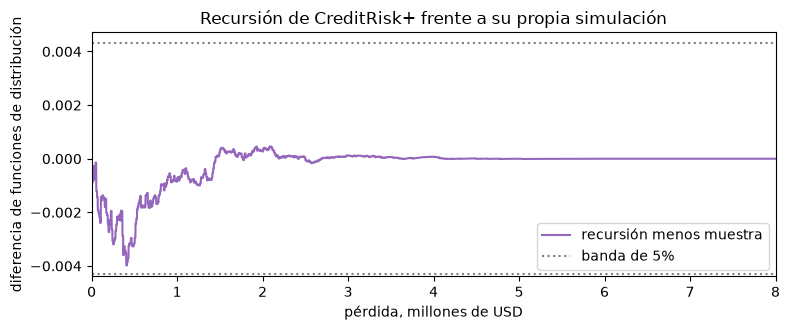

In [12]:
# Dibujar la diferencia entre las funciones de distribución de la recursión y de la muestra
counts = np.bincount(np.minimum(sample_units, pmf.size - 1), minlength=pmf.size)
difference = np.cumsum(pmf) - np.cumsum(counts) / n_mc
band = 1.36 / np.sqrt(n_mc)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(np.arange(pmf.size) * loss_unit / 1e6, difference, color="tab:purple", label="recursión menos muestra")
ax.axhline(band, color="gray", linestyle=":", label="banda de 5%")
ax.axhline(-band, color="gray", linestyle=":")
ax.set_xlim(0, 8)
ax.set_xlabel("pérdida, millones de USD")
ax.set_ylabel("diferencia de funciones de distribución")
ax.set_title("Recursión de CreditRisk+ frente a su propia simulación")
ax.legend()
fig.tight_layout()
plt.show()

La curva ronda el cero y se queda dentro de la banda punteada, que es el ancho que produciría el ruido de muestreo solo con 100.000 escenarios. Su mayor excursión es la distancia de Kolmogorov impresa arriba, y la prueba sale verde porque ninguna excursión sale de la banda. Los dos cálculos comparten el modelo Poisson-Gamma y nada más: la recursión es aritmética exacta sobre una función generadora y la muestra son sorteos aleatorios, así que el acuerdo significa que la recursión implementa el modelo que dice implementar. No significa que el modelo ajuste incumplimientos reales, y la prueba saldría roja de inmediato si una probabilidad fuera negativa.

La última celda pone los métodos lado a lado. Para la misma cartera y la misma PD y correlación ajustadas toma el VaR al 99,9% del límite de la cartera grande, de CreditRisk+, de la cópula gaussiana por Monte Carlo y del límite más el ajuste por granularidad, y los dibuja como barras. La brecha entre el primero y los demás es el precio de una cartera finita y concentrada.

método                                          VaR 99.9%      razón al límite
Límite de cartera grande                        2,298,833                1.000
CreditRisk+                                     3,078,000                1.339
Cópula gaussiana, Monte Carlo                   3,150,000                1.370
Límite + ajuste por granularidad                3,281,809                1.428


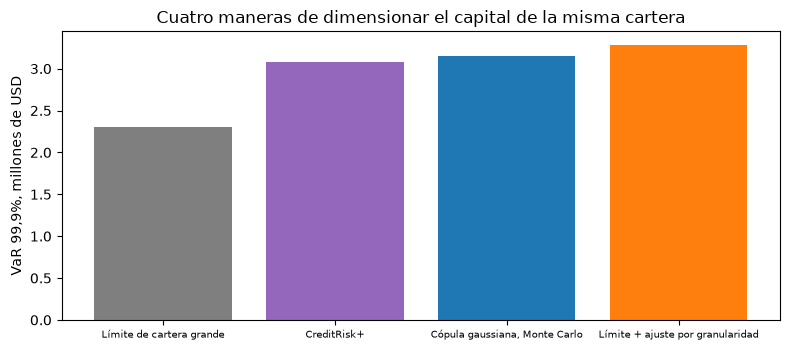

In [13]:
# Comparar el VaR al 99,9% de cuatro métodos sobre la misma cartera
ga_money, var_limit = adjustment[0.999]
var_mc = pf.measures_from_sample(sample.losses, (0.999,), pf.expected_loss(one))[0].var
comparison = {
    "Límite de cartera grande": var_limit,
    "CreditRisk+": measures[1].var,
    "Cópula gaussiana, Monte Carlo": var_mc,
    "Límite + ajuste por granularidad": var_limit + ga_money,
}
print(f"{'método':44s} {'VaR 99.9%':>12s} {'razón al límite':>20s}")
for name, value in comparison.items():
    print(f"{name:44s} {value:12,.0f} {value / var_limit:20.3f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = ["tab:gray", "tab:purple", "tab:blue", "tab:orange"]
ax.bar(range(len(comparison)), np.array(list(comparison.values())) / 1e6, color=colors)
ax.set_xticks(range(len(comparison)), list(comparison), fontsize=7)
ax.set_ylabel("VaR 99,9%, millones de USD")
ax.set_title("Cuatro maneras de dimensionar el capital de la misma cartera")
fig.tight_layout()
plt.show()

La primera barra es lo que dice la fórmula cerrada y las otras tres son lo que necesita una cartera finita y concentrada. CreditRisk+, la cópula gaussiana simulada y el límite más el ajuste caen entre 3,0 y 3,3 millones de USD, cerca de un tercio sobre la fórmula, así que las tres rutas distintas coinciden en el tamaño del efecto de concentración aunque comparten solo la PD y la correlación. El ajuste es el que no necesita simulación ni recursión, una sola fórmula sobre las participaciones de exposición, y por eso un supervisor puede usarlo. Las barras no ordenan los métodos: cada uno descansa en un supuesto de dependencia distinto, y la cola real de una cartera bancaria no se conoce.

## Resultados

**Respuesta:** CreditRisk+ pone el valor en riesgo al 99,9% de la cartera de 1.120 nombres en 3.078.000 USD (capital de 2.668.279 USD) sin ninguna simulación, un tercio sobre el límite de la cartera grande de 2.298.833 USD, y el ajuste por granularidad de 982.976 USD al 99,9% explica esa concentración, llevando el límite a 3.281.809 USD.

- **La recursión da toda la distribución de pérdidas de forma exacta, y su ancla se cumple.** Para la cartera de 1.120 nombres la recursión estable pone masa 1,0 en una grilla de 12.728 unidades sin ninguna entrada negativa, y su primera probabilidad, 1,546187529037e-02, es igual a la forma cerrada $(1+\sigma^2\mu)^{-1/\sigma^2}$ hasta los dígitos impresos, con $\sigma^2=0{,}552066$ obtenido integrando la PD condicional del notebook 01. El VaR al 99% y al 99,9% es 2.079.000 y 3.078.000 USD y el déficit esperado 2.514.778 y 3.506.025 USD.
- **CreditRisk+ y la cópula gaussiana coinciden en el cuerpo y se separan algo en la cola.** Las dos curvas de la figura corren juntas hasta la línea del 0,1%; la actuarial queda algo más baja en la cola lejana. Ambas están muy sobre el límite de la cartera grande, porque la cartera está concentrada.
- **La recursión original falla donde la estable no.** En la cartera del caso las recursiones de Panjer y estable coinciden hasta 2,1e-17. En la cartera de estrés construida de 30.000 nombres y 8 sectores la recursión estable mantiene toda entrada dentro de [0, 1] mientras la de Panjer produce 2.406 entradas negativas y probabilidades que suman -7,01. Por eso el motor usa la recursión estable para su capital y deja la original solo como comparación.
- **El ajuste por granularidad suma cerca de un tercio al capital de la cartera grande.** Con el $\xi=0{,}25$ del artículo, $\delta=4{,}8336$ al 99,9%, el ajuste es 481.771 USD al 99% y 982.976 USD al 99,9%, 0,428 del VaR de la cartera grande al 99,9%. El VaR de la cartera grande más el ajuste es 3.281.809 USD, en el rango de los otros dos métodos.
- **El ajuste sobreestima la brecha exacta en carteras pequeñas.** Para carteras de tarjetas de crédito de 10, 100 y 1.000 nombres, la fórmula da 1,49, 1,32 y 1,51 veces la brecha exacta de CreditRisk+; GA por n es constante en 1,8158, como dice la proporcionalidad con el HHI. Para la cartera comercial el peso implícito sobre el factor sistemático es 1,055, fuera de (0, 1], así que no existe respuesta exacta: la comparación es una propiedad de los supuestos del modelo, no un defecto del motor.
- **La recursión coincide con su propia simulación.** Contra 100.000 escenarios la distancia de Kolmogorov es 0,00398, p = 0,0843 y verde, sin entradas negativas. La prueba certifica la implementación del modelo, no el modelo.

Lo que este notebook no muestra: cómo se reparte el capital entre nombres y grupos (notebook 05), qué estructura de dependencia tienen los bancos reales, ni la incertidumbre de la correlación detrás de cada número. La cartera es ilustrativa, nunca la de un banco.

## Resumen

- CreditRisk+ modela los incumplimientos como conteos de Poisson gobernados por un factor Gamma; su distribución de pérdidas sale de una recursión sobre la función generadora, sin simulación, y `pmf_stable` es exacta y no negativa.
- La recursión original de Panjer resta términos de signo opuesto y falla en una cartera grande de varios sectores; el motor la conserva solo como comparación.
- El ajuste por granularidad (`granularity_adjustment`, `delta`) reproduce el vector de prueba del artículo y suma 42,8% al VaR de la cartera grande al 99,9%.
- Frente a la brecha exacta de CreditRisk+ de nombres idénticos, la fórmula sobrestima entre 32% y 51% en la cartera de tarjetas, y una cartera cuyo peso implícito sobre el factor queda fuera de (0, 1] no tiene respuesta exacta.
- `crp_recursion_vs_mc` prueba la recursión contra una simulación de su propio modelo.

**Qué probar a continuación.** Cambia el número de nombres del Paso 5 a 20 y 500 para tarjetas y compara la fórmula con la brecha exacta. Luego abre el notebook 05, donde el capital de la cartera se reparte entre sus grupos.

## Referencias

- Haaf, H., Reiss, O. y Schoenmakers, J. (2004), Numerically stable computation of CreditRisk+, Journal of Risk 6(4):1-10. https://doi.org/10.21314/jor.2004.097
- Gordy, M. B. y Lutkebohmert, E. (2013), Granularity adjustment for regulatory capital assessment, International Journal of Central Banking 9(3):33-48. https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- BCBS, Basel Framework, CRE31: IRB approach, risk weight functions for corporate, bank, sovereign and retail exposures. https://www.bis.org/basel_framework/chapter/CRE/31.htm
- Acerbi, C. y Tasche, D. (2002), On the coherence of expected shortfall, Journal of Banking and Finance 26(7):1487-1503. https://doi.org/10.1016/S0378-4266(02)00283-2
- Federal Reserve charge-off table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm (public domain; licence class mirror-allowed).
- Credit Suisse First Boston (1997), CreditRisk+: A Credit Risk Management Framework, the original model document: not accessed by the persisted research (UNVERIFIED primary); the model statement is verified from Haaf, Reiss and Schoenmakers (2004).
- Persisted research dossier 04 of this product (credit-risk models, state of the art), sections H.4 and H.5 (CreditRisk+ and the granularity adjustment).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.